# Oportunidades e Recomendação

Análise de oportunidades de negócio e recomendações estratégicas a partir da base de
pedidos da Olist, cruzando resultados de frete, pricing e desempenho de sellers. São
avaliados:

- **Frete em rotas críticas:** rotas (UF do seller → UF do cliente) onde o frete pesa
  demais sobre o valor do produto e a entrega é mais lenta
- **Pricing e cross-sell:** categorias e regiões com maior ticket médio e maior
  propensão a pedidos com múltiplos itens
- **Priorização de sellers:** cruzamento entre nota de avaliação e tempo de entrega
  para decidir quem priorizar, quem investigar e quem colocar em plano de ação


## 1. Importações

#### Instalando as bibliotecas

In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


#### Importando as bibliotecas

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carregamento dos dados

#### Carregando os CSVs

In [3]:
PASTA = "../data/"

orders    = pd.read_csv(PASTA + "olist_orders_dataset.csv")
items     = pd.read_csv(PASTA + "olist_order_items_dataset.csv")
customers = pd.read_csv(PASTA + "olist_customers_dataset.csv")
sellers   = pd.read_csv(PASTA + "olist_sellers_dataset.csv")
products  = pd.read_csv(PASTA + "olist_products_dataset.csv")
reviews   = pd.read_csv(PASTA + "olist_order_reviews_dataset.csv")
traducao  = pd.read_csv(PASTA + "product_category_name_translation.csv")

#### Conferindo o tamanho das tabelas

In [4]:
print("orders:", orders.shape)
print("items:", items.shape)
print("customers:", customers.shape)
print("sellers:", sellers.shape)
print("products:", products.shape)
print("reviews:", reviews.shape)
print("traducao:", traducao.shape)

orders: (99441, 8)
items: (112650, 7)
customers: (99441, 5)
sellers: (3095, 4)
products: (32951, 9)
reviews: (99224, 7)
traducao: (71, 2)


## 3. Tratamento dos dados

#### Convertendo datas e filtrando entregues

In [5]:
colunas_data = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

for col in colunas_data:
    orders[col] = pd.to_datetime(orders[col])

entregues = orders[orders["order_status"] == "delivered"].copy()

print("Total de pedidos:", len(orders))
print("Pedidos entregues:", len(entregues))

Total de pedidos: 99441
Pedidos entregues: 96478


#### Padronizando cores

In [6]:
COR_PRINCIPAL = "#364ef7"   # azul (brand1): leitura neutra
COR_DESTAQUE = "#d23718"    # vermelho (brand4): o que merece atenção
COR_NEUTRA = "#696d8c"      # cinza neutro: linhas de referência

#### Removendo nulos

In [7]:
antes = len(entregues)

entregues = entregues.dropna(subset=[
    "order_approved_at",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
])

print("Removidos por data nula:", antes - len(entregues))
print("Restantes:", len(entregues))

Removidos por data nula: 22
Restantes: 96456


#### Calculando lead time e atraso

In [8]:
def dias(fim, inicio):
    return (fim - inicio).dt.total_seconds() / 86400

entregues["lead_time"] = dias(entregues["order_delivered_customer_date"], entregues["order_purchase_timestamp"])
entregues["atraso"] = dias(entregues["order_delivered_customer_date"], entregues["order_estimated_delivery_date"])

#### Traduzindo categoria de produto

In [9]:
products_t = products.merge(traducao, on="product_category_name", how="left")
products_t["categoria"] = products_t["product_category_name_english"].fillna(products_t["product_category_name"])

#### Montando a base única (item + pedido + cliente + seller + produto + nota)

In [10]:
nota_pedido = reviews.groupby("order_id", as_index=False)["review_score"].mean()

base = (
    items
    .merge(entregues, on="order_id", how="inner")
    .merge(customers, on="customer_id", how="left")
    .merge(sellers, on="seller_id", how="left")
    .merge(products_t[["product_id", "categoria"]], on="product_id", how="left")
    .merge(nota_pedido, on="order_id", how="left")
)

base["frete_pct"] = base["freight_value"] / base["price"].replace(0, np.nan) * 100

print("Linhas na base final:", len(base))
print("Pedidos únicos:", base["order_id"].nunique())

Linhas na base final: 110174
Pedidos únicos: 96456


## 4. Frete em rotas críticas

#### Desempenho por rota (UF do seller → UF do cliente)

In [11]:
rota = (
    base.groupby(["seller_state", "customer_state"])
    .agg(
        pedidos=("order_id", "nunique"),
        preco_medio=("price", "mean"),
        frete_medio=("freight_value", "mean"),
        frete_pct_medio=("frete_pct", "mean"),
        lead_time_medio=("lead_time", "mean"),
        receita_total=("price", "sum"),
    )
    .reset_index()
)

print("Combinações de rota encontradas:", len(rota))

Combinações de rota encontradas: 412


#### Filtrando rotas com volume relevante e calculando criticidade

In [12]:
MIN_PEDIDOS_ROTA = 30

rota_valida = rota[rota["pedidos"] >= MIN_PEDIDOS_ROTA].copy()

rota_valida["criticidade"] = (
    rota_valida["frete_pct_medio"].rank(pct=True)
    + rota_valida["lead_time_medio"].rank(pct=True)
) / 2

top_rotas = rota_valida.sort_values("criticidade", ascending=False).head(10)
top_rotas[[
    "seller_state", "customer_state", "pedidos", "preco_medio", "frete_medio",
    "frete_pct_medio", "lead_time_medio", "receita_total",
]].round(1)

,seller_state,customer_state,pedidos,preco_medio,frete_medio,frete_pct_medio,lead_time_medio,receita_total
406,SP,RR,33,156.2,42.0,56.5,30.4,5777.7
168,MG,SE,36,126.9,42.6,56.7,25.1,5204.5
157,MG,PA,84,140.6,44.6,54.4,27.8,12932.8
394,SP,MA,492,122.6,38.4,61.0,22.2,67169.5
387,SP,AM,99,119.4,30.9,52.9,26.2,13010.2
386,SP,AL,256,152.4,34.4,52.7,24.6,41593.4
153,MG,MA,64,133.6,49.1,60.5,20.1,8949.2
405,SP,RO,169,135.3,40.6,63.4,20.0,26379.8
399,SP,PB,337,170.7,43.3,55.2,20.7,66074.0
258,PR,CE,64,205.4,41.9,48.6,24.0,14791.9


#### Gráfico das rotas mais críticas

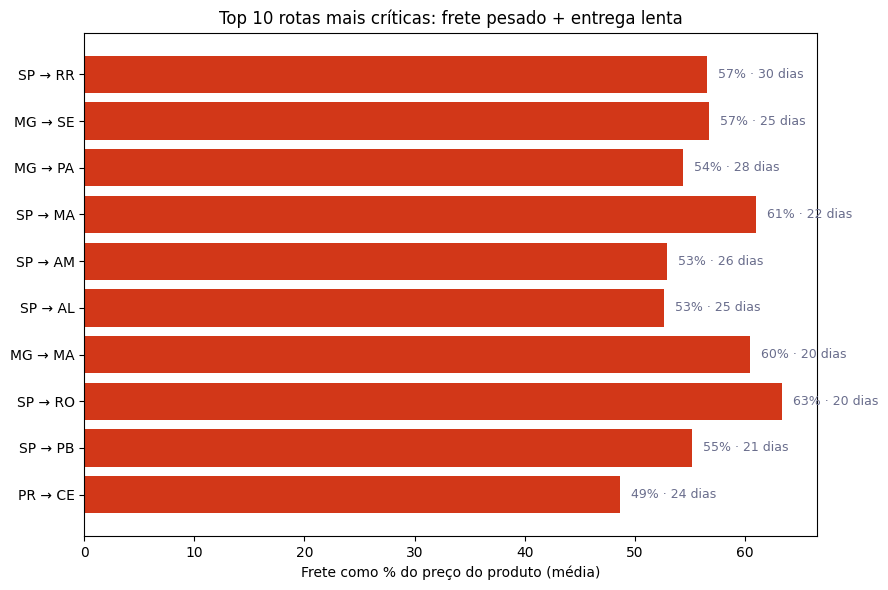

In [13]:
limite_destaque = rota_valida["criticidade"].quantile(0.8)
cores = [COR_DESTAQUE if c >= limite_destaque else COR_PRINCIPAL for c in top_rotas["criticidade"]]
rotulo = top_rotas["seller_state"] + " \u2192 " + top_rotas["customer_state"]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(rotulo[::-1], top_rotas["frete_pct_medio"][::-1], color=cores[::-1])
ax.set_xlabel("Frete como % do preço do produto (média)")
ax.set_title("Top 10 rotas mais críticas: frete pesado + entrega lenta")

for i, (pct, lt) in enumerate(zip(top_rotas["frete_pct_medio"][::-1], top_rotas["lead_time_medio"][::-1])):
    ax.text(pct + 1, i, f"{pct:.0f}% · {lt:.0f} dias", va="center", fontsize=9, color=COR_NEUTRA)

plt.tight_layout()
plt.show()

**Leitura do resultado:** um pequeno grupo de rotas interestaduais concentra frete
desproporcional ao valor do produto e entregas mais lentas que a média. A rota São
Paulo → Maranhão é a de maior volume dentro desse grupo (centenas de pedidos), com o
frete consumindo mais da metade do valor do produto e lead time acima de três semanas.
Rotas de menor volume mas igual criticidade (SP → RR, MG → SE, MG → PA, SP → AM)
reforçam o padrão: frete entre 53% e 61% do preço, com entregas de 22 a 30 dias.

**Recomendação:** priorizar a renegociação de frete e avaliar um hub de distribuição
regional por essas rotas específicas — não pela malha logística inteira. É onde o
retorno por real investido é maior, seja pelo volume (SP → MA), seja pelo custo
percentual (demais rotas).

## 5. Pricing e cross-sell por categoria e região

#### Marcando pedidos com múltiplos itens

In [14]:
itens_por_pedido = items.groupby("order_id")["order_item_id"].count().rename("n_itens")
base = base.merge(itens_por_pedido, on="order_id", how="left")
base["multi_item"] = base["n_itens"] > 1

print("Taxa geral de pedidos com múltiplos itens:", f"{base['multi_item'].mean():.1%}")

Taxa geral de pedidos com múltiplos itens: 21.2%


#### Desempenho por categoria

In [15]:
categoria = (
    base.groupby("categoria")
    .agg(
        pedidos=("order_id", "nunique"),
        receita_total=("price", "sum"),
        ticket_medio=("price", "mean"),
        taxa_multi_item=("multi_item", "mean"),
        nota_media=("review_score", "mean"),
    )
    .reset_index()
)

MIN_PEDIDOS_CAT = 50
categoria_valida = categoria[categoria["pedidos"] >= MIN_PEDIDOS_CAT].copy()

top_cross_sell = categoria_valida.sort_values("taxa_multi_item", ascending=False).head(10)
top_cross_sell.round(2)

,categoria,pedidos,receita_total,ticket_medio,taxa_multi_item,nota_media
64,signaling_and_security,138,21315.05,108.20,0.48,4.09
39,furniture_decor,6304,711672.09,87.25,0.40,3.95
57,office_furniture,1254,268154.31,160.76,0.39,3.51
21,costruction_tools_garden,190,25096.28,108.17,0.37,4.12
18,construction_tools_lights,242,39957.00,132.75,0.36,4.08
48,home_construction,483,81407.57,136.59,0.35,3.96
42,garden_tools,3447,470360.28,110.23,0.33,4.08
24,drinks,287,21529.84,59.64,0.33,4.12
17,construction_tools_construction,736,142108.49,155.14,0.32,4.09
37,food_drink,221,14942.88,55.55,0.30,4.37


#### Gráfico: ticket médio x taxa de cross-sell por categoria

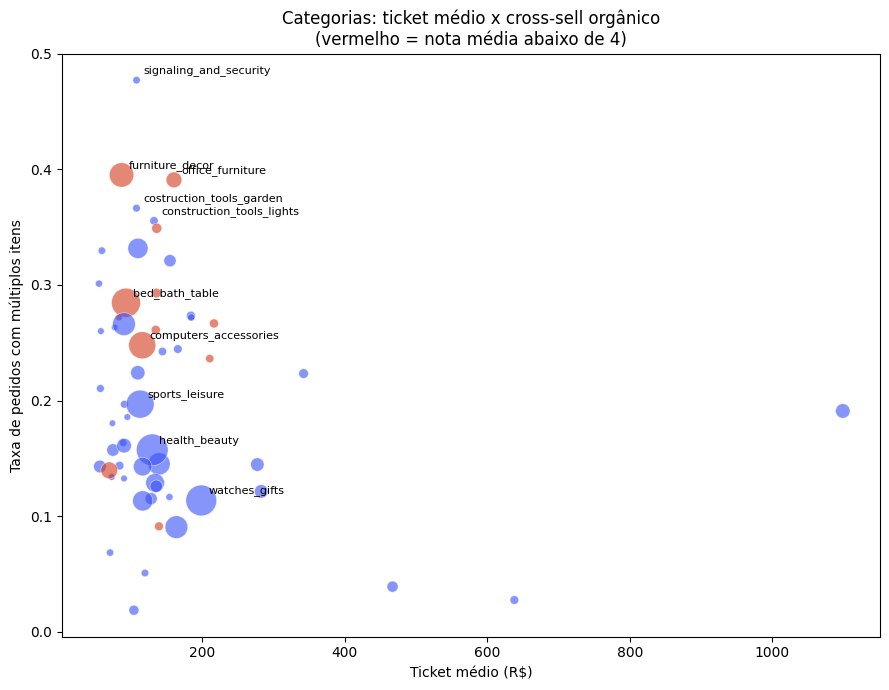

In [16]:
fig, ax = plt.subplots(figsize=(9, 7))
cores_pontos = [COR_DESTAQUE if n < 4 else COR_PRINCIPAL for n in categoria_valida["nota_media"]]

ax.scatter(
    categoria_valida["ticket_medio"],
    categoria_valida["taxa_multi_item"],
    s=categoria_valida["receita_total"] / categoria_valida["receita_total"].max() * 500 + 20,
    c=cores_pontos,
    alpha=0.6,
    edgecolor="white",
    linewidth=0.5,
)

destacar = pd.concat([
    categoria_valida.sort_values("receita_total", ascending=False).head(5),
    top_cross_sell.head(5),
]).drop_duplicates("categoria")

for _, r in destacar.iterrows():
    ax.annotate(r["categoria"], (r["ticket_medio"], r["taxa_multi_item"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Ticket médio (R$)")
ax.set_ylabel("Taxa de pedidos com múltiplos itens")
ax.set_title("Categorias: ticket médio x cross-sell orgânico\n(vermelho = nota média abaixo de 4)")
plt.tight_layout()
plt.show()

#### Maiores combinações de receita por estado e categoria

In [17]:
regiao_categoria = (
    base.groupby(["customer_state", "categoria"])
    .agg(pedidos=("order_id", "nunique"), receita_total=("price", "sum"))
    .reset_index()
)

top_combo_regional = (
    regiao_categoria[regiao_categoria["pedidos"] >= 20]
    .sort_values("receita_total", ascending=False)
    .head(10)
)
top_combo_regional.round(2)

,customer_state,categoria,pedidos,receita_total
1259,SP,bed_bath_table,4347,472238.07
1295,SP,health_beauty,3715,453916.48
1323,SP,watches_gifts,2088,421268.60
1318,SP,sports_leisure,3214,374975.89
1267,SP,computers_accessories,2615,340933.97
1291,SP,furniture_decor,2664,277776.46
1301,SP,housewares,2720,269656.60
1257,SP,auto,1584,209231.14
1272,SP,cool_stuff,1289,208602.89
1322,SP,toys,1576,179898.56


**Leitura do resultado:** categorias como móveis e decoração e móveis de escritório
combinam ticket médio alto, cross-sell orgânico relevante (quase 4 em cada 10 pedidos
com mais de um item) e nota de avaliação saudável — já vendem em conjunto sem nenhum
incentivo comercial direcionado. São Paulo concentra os maiores combos
categoria-receita do país, volume suficiente para testar bundles antes de replicar em
outras regiões.

**Recomendação:** lançar campanhas de "compre junto" começando pelas categorias de
maior receita e cross-sell comprovados, testando em São Paulo antes de expandir.
Categorias de ticket baixo e cross-sell baixo não justificam investimento de marketing
dedicado agora.

## 6. Priorização de sellers (NPS x tempo de entrega)

#### Desempenho por seller

In [18]:
seller_perf = (
    base.groupby("seller_id")
    .agg(
        pedidos=("order_id", "nunique"),
        receita_total=("price", "sum"),
        nota_media=("review_score", "mean"),
        lead_time_medio=("lead_time", "mean"),
    )
    .reset_index()
)

MIN_PEDIDOS_SELLER = 20
seller_valido = seller_perf[seller_perf["pedidos"] >= MIN_PEDIDOS_SELLER].copy()

print("Sellers com volume relevante:", len(seller_valido))

Sellers com volume relevante: 804


#### Classificando em quadrantes

In [19]:
lead_time_mediana = seller_valido["lead_time_medio"].median()
nota_mediana = seller_valido["nota_media"].median()

def quadrante(linha):
    rapido = linha["lead_time_medio"] <= lead_time_mediana
    boa_nota = linha["nota_media"] >= nota_mediana
    if rapido and boa_nota:
        return "Priorizar"
    if not rapido and boa_nota:
        return "Potencial travado por logística"
    if rapido and not boa_nota:
        return "Investigar insatisfação"
    return "Plano de ação"

seller_valido["quadrante"] = seller_valido.apply(quadrante, axis=1)
seller_valido["quadrante"].value_counts()

quadrante
Plano de ação                      267
Priorizar                          267
Potencial travado por logística    135
Investigar insatisfação            135
Name: count, dtype: int64

#### Gráfico dos quadrantes

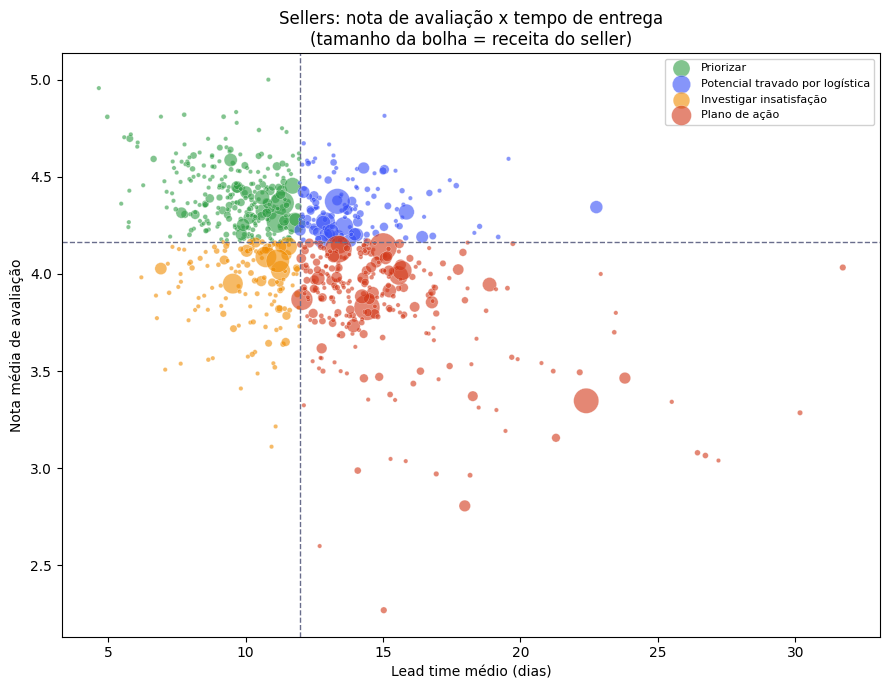

In [20]:
cores_quadrante = {
    "Priorizar": "#2f9e44",
    "Potencial travado por logística": COR_PRINCIPAL,
    "Investigar insatisfação": "#f08c00",
    "Plano de ação": COR_DESTAQUE,
}

fig, ax = plt.subplots(figsize=(9, 7))
for quad, cor in cores_quadrante.items():
    sub = seller_valido[seller_valido["quadrante"] == quad]
    ax.scatter(
        sub["lead_time_medio"], sub["nota_media"],
        s=np.clip(sub["receita_total"] / seller_valido["receita_total"].max() * 400, 10, 400),
        c=cor, alpha=0.6, label=quad, edgecolor="white", linewidth=0.3,
    )

ax.axvline(lead_time_mediana, color=COR_NEUTRA, linestyle="--", linewidth=1)
ax.axhline(nota_mediana, color=COR_NEUTRA, linestyle="--", linewidth=1)
ax.set_xlabel("Lead time médio (dias)")
ax.set_ylabel("Nota média de avaliação")
ax.set_title("Sellers: nota de avaliação x tempo de entrega\n(tamanho da bolha = receita do seller)")
ax.legend(loc="upper right", fontsize=8, framealpha=0.9)
plt.tight_layout()
plt.show()

#### Sellers de maior receita no quadrante 'Potencial travado por logística'

In [21]:
(
    seller_valido[seller_valido["quadrante"] == "Potencial travado por logística"]
    .sort_values("receita_total", ascending=False)
    .head(5)
    [["seller_id", "pedidos", "receita_total", "nota_media", "lead_time_medio"]]
)

,seller_id,pedidos,receita_total,nota_media,lead_time_medio
2903,fa1c13f2614d7b5c4749cbc52fecda94,578,190917.14,4.373913,13.341871
1156,620c87c171fb2a6dd6e8bb4dec959fc6,722,112461.50,4.267974,12.905887
1881,a1043bafd471dff536d0c462352beb48,702,99309.23,4.246667,13.586723
2396,ccc4bbb5f32a6ab2b7066a4130f114e3,184,72926.72,4.319149,15.853247
2877,f7ba60f8c3f99e7ee4042fdef03b70c4,218,68070.00,4.218341,13.124416


**Leitura do resultado:** entre os sellers com volume relevante, uma parte recebe
boa nota de avaliação mas entrega acima da mediana de dias — são sellers cujo produto
já agrada o cliente, mas que perdem venda e nota por causa da cadeia de entrega. No
outro extremo, há sellers de alto volume com nota abaixo da mediana e entrega lenta
simultaneamente, concentrando o maior risco reputacional da base.

**Recomendação:** tratar o quadrante "Potencial travado por logística" como prioridade
imediata de parceria comercial — é o ganho mais rápido, porque o produto já foi
validado pelo cliente. O quadrante "Plano de ação" de maior receita deve ser prioridade
de auditoria, por concentrar maior exposição financeira e reputacional ao mesmo tempo.

## 7. Conclusões e recomendações

**Resumo:** um pequeno grupo de rotas concentra frete desproporcional e entrega
lenta; algumas categorias já comprovam cross-sell orgânico e sustentam ticket médio
mais alto; e um grupo específico de sellers tem produto validado pelo cliente mas é
penalizado pela própria logística da Olist. As três frentes apontam na mesma direção:
o maior ganho de curto prazo está em consertar a entrega nos pontos já identificados,
não em ações genéricas sobre toda a base.

### Conclusões

**1. O frete crítico está concentrado, não espalhado.** Rotas como São Paulo →
Maranhão (maior volume) e São Paulo → Roraima, Minas Gerais → Sergipe/Pará e São
Paulo → Amazonas (maior custo percentual) combinam frete acima de 50% do valor do
produto com lead time de 22 a 30 dias.

**2. O cross-sell já acontece de forma orgânica em categorias específicas.** Móveis e
decoração, móveis de escritório e sinalização e segurança sustentam ticket médio
mais alto e taxa de pedidos com múltiplos itens bem acima da média — sinal de demanda
complementar real, não de hipótese.

**3. Parte dos sellers mais bem avaliados está sendo prejudicada pela logística, não
pelo produto.** Esse grupo é o de maior alavancagem de curto prazo: resolver o tempo de
entrega desses sellers tende a se converter diretamente em mais vendas e melhor nota,
sem exigir nenhuma mudança de catálogo.

**4. As três recomendações se reforçam mutuamente.** Atacar as rotas críticas de frete
beneficia diretamente os sellers do quadrante "Potencial travado por logística" que
operam nessas regiões, e libera espaço para investir em cross-sell nas categorias já
validadas sem o risco de frustrar o cliente com atraso.

> Tabelas de apoio completas (rankings de rotas, categorias e sellers) podem ser
> reproduzidas a partir deste notebook, célula a célula, para consulta ou atualização
> conforme a base evoluir.